# Submission 3 &ndash; Final Submission

## Instructions

- Fill out the *Basic Information* and the *Results* sections.
- Make sure that this `.ipynb` file displays correctly in the GitHub file preview, including any visual output.
- If you find that any output does not display correctly, include a static screenshot as an image. For interactive outputs, add a link to a short screencast located in your repository.
- Push all required files before the deadline.

---
## Basic Information

**Team Name:** Grafica

**Team Members:**
- Amr Abdullah
- Mihajlo Živić
- Marlon Orta
- Mohammad Shadik Ansari

**Dataset Description:**  
(max. 75 words; this serves just as a reminder)

The dataset “Suicide Rates Overview 1985–2016” from kaggle compiles global suicide data and socio‑economic indicators collected by the United Nations Development Program (2018), the World Health Organization (2018), and the World Bank (2018). Each record includes the following attributes: country, year, sex, age group, number of suicides, population, suicides per 100k, HDI, GDP for the year, GDP per capita, and a generation label. We selected this dataset because it contains diverse numerical, categorical, and demographic attributes that support meaningful analysis of suicide, a major global public health issue influenced by economic conditions and demographic patterns. The dataset is also clean, well structured, and easy to interpret. It includes over 27,000 rows and 12 columns, covering multiple countries across different continents from 1985 to 2016. The data is not synthetic; it was scraped from various NGOs.

---

## Code

Here you may place any code that is not an immediate part of your submission. Only the content of the *Results* sections will be graded for this submission.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

dataset_path = kagglehub.dataset_download("russellyates88/suicide-rates-overview-1985-to-2016")
df_raw = pd.read_csv(f"{dataset_path}/master.csv")

# Cleaning pipeline (reused from sub_02_intermediate)
df = df_raw.rename(columns={
    "suicides/100k pop": "suicides_per_100k",
    "country-year": "country_year",
    "HDI for year": "hdi_for_year",
    " gdp_for_year ($) ": "gdp_for_year",
    "gdp_per_capita ($)": "gdp_per_capita",
})

# clean out the separators from gdp_for_year and convert to float
if df["gdp_for_year"].dtype == object:
    df["gdp_for_year"] = (df["gdp_for_year"].astype(str)
                          .str.replace(",", "", regex=False).astype(float))
df["gdp_per_capita"] = pd.to_numeric(df["gdp_per_capita"], errors="coerce")

# Drop empty HDI column and the incomplete 2016 reporting year
df = df.drop(columns=["hdi_for_year"], errors="ignore")
df = df[df["year"] != 2016].copy()

# Ordered age categorical + decade helper column
age_order = ["5-14 years", "15-24 years", "25-34 years",
             "35-54 years", "55-74 years", "75+ years"]
df["age"] = pd.Categorical(df["age"], categories=age_order, ordered=True)
df["decade"] = (df["year"] // 10) * 10

# Drop countries with very sparse reporting (<= 3 years)
year_counts = df.groupby("country")["year"].nunique()
df = df[df["country"].isin(year_counts[year_counts > 3].index)].copy()

# Population-weighted rate helper (reused from sub_02)
def rate_per_100k(suicides, population):
    """Population-weighted suicide rate: total suicides / total population * 100k."""
    return suicides.sum() / population.sum() * 100_000

print(f"Cleaned rows: {len(df):,} | years {df['year'].min()}-{df['year'].max()} "
      f"| countries {df['country'].nunique()}")


Cleaned rows: 27,492 | years 1985-2015 | countries 93


In [ ]:
# B.1 visualization 
def plot_gdp_vs_rate_by_age(df, n_bins=10):
    d = df.dropna(subset=["gdp_per_capita", "population"]).copy()
    d["gdp_bin"] = pd.qcut(d["gdp_per_capita"], q=n_bins)
    grp = (d.groupby(["gdp_bin", "age"], observed=True)
             .agg(suicides=("suicides_no", "sum"),
                  population=("population", "sum"),
                  gdp=("gdp_per_capita", "median")).reset_index())
    grp["rate"] = grp["suicides"] / grp["population"] * 100_000

    colors = {age: plt.cm.viridis(i / (len(age_order) - 1))
              for i, age in enumerate(age_order)}
    fig, ax = plt.subplots(figsize=(11, 6.5))
    for age in age_order:
        sub = grp[grp["age"] == age].sort_values("gdp")
        ax.plot(sub["gdp"], sub["rate"], marker="o", ms=5, lw=2,
                color=colors[age], label=age)
    ax.set_xscale("log")

    tick_positions = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000] # standarize scale 
    tick_labels    = ["$1k", "$2k", "$5k", "$10k", "$20k", "$50k", "$100k"]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, fontsize=10)
    ax.xaxis.set_minor_locator(plt.NullLocator())  

    ax.set_xlabel("GDP per capita (USD, log scale)", fontsize=12)
    ax.set_ylabel("Suicide rate (per 100k, population-weighted)", fontsize=12)
    ax.set_title("B.1 — Suicide rate vs. GDP per capita, by age group", fontsize=14)
    ax.grid(True, ls=":", lw=0.5, alpha=0.6)
    ax.legend(title="Age group", frameon=False, fontsize=6, loc="upper right")
    fig.tight_layout()
    plt.show()

In [3]:
# B.2 visualization function  
def plot_gender_evolution(df, early_by=1990, late_by=2010, min_years=20, min_pop=1_000_000):
    g = (df.groupby(["country", "year", "sex"], observed=True)
           .agg(suicides=("suicides_no", "sum"), population=("population", "sum"))
           .reset_index())
    g["rate"] = g["suicides"] / g["population"] * 100_000
    piv = g.pivot_table(index=["country", "year"], columns="sex", values="rate").reset_index()
    piv["gap"] = piv["male"] - piv["female"]

    span = piv.groupby("country")["year"].agg(first="min", last="max", n="nunique")
    mean_pop = df.groupby(["country", "year"])["population"].sum().groupby("country").mean()
    eligible = span.index[(span["first"] <= early_by) & (span["last"] >= late_by)
                          & (span["n"] >= min_years) & (mean_pop >= min_pop)]
    piv = piv[piv["country"].isin(eligible)]

    slopes = pd.Series({c: np.polyfit(d["year"], d["gap"], 1)[0]
                        for c, d in piv.groupby("country")
                        if d["year"].nunique() >= 2}).sort_values()
    selected = slopes.tail(3).index[::-1].tolist() + slopes.head(3).index.tolist()
    labels = ["diverging"] * 3 + ["converging"] * 3

    MALE, FEMALE = "#1f6f8b", "#d1495b"
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True, sharey=True)  
    for ax, country, lab in zip(axes.ravel(), selected, labels):
        d = piv[piv["country"] == country].sort_values("year")
        ax.fill_between(d["year"], d["female"], d["male"], color="gray", alpha=0.12)
        ax.plot(d["year"], d["male"], color=MALE, lw=2, marker="o", ms=3, label="Male")
        ax.plot(d["year"], d["female"], color=FEMALE, lw=2, marker="o", ms=3, label="Female")
        ax.set_title(f"{country} — {lab}", fontsize=11)
        ax.set_ylim(0, 85)   
        ax.grid(True, ls=":", lw=0.5, alpha=0.6)
    axes[0, 0].legend(frameon=False, fontsize=9)

    fig.supxlabel("Year", fontsize=12)
    fig.supylabel("Suicide rate (per 100k, population-weighted)", fontsize=12)
    fig.suptitle("B.2 — Male vs. female rate evolution: strongest divergence (top row) "
                 "and convergence (bottom row)", fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

---
## Results &ndash; Complex Hypotheses/Tasks

### B.1

Restate your hypothesis/task below.

**Hypthesis/~~Task~~ B.1:** The relationship between GDP per capita and suicide rates varies by age group.

Place your visualizations below (max. 2). Make sure that everyting displays correctly in the GitHub file preview.

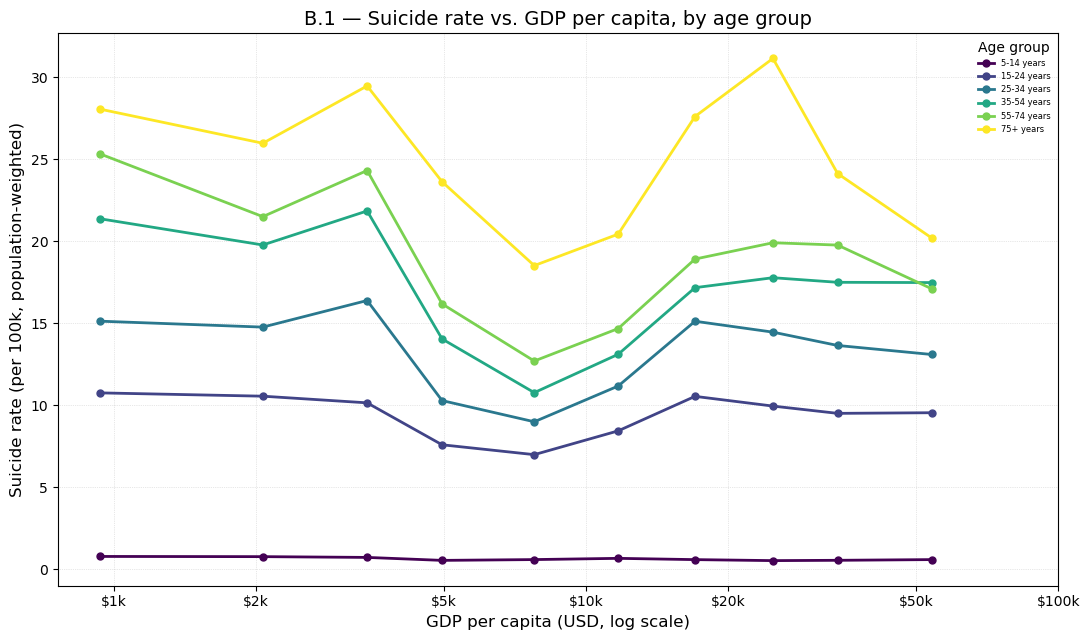

In [4]:
plot_gdp_vs_rate_by_age(df)

Describe your visualizations and findings. Be clear which chart(s) you are referring to and relate your findings to the hypothesis/task.
Use no more than 150 words and indicate the word count of your description below.

**Description:** 
The line chart B.1 illustrates suicide rates per 100k against GDP per capita in log scale for six different age categories. Rates are categorized by age, with older groups (75+, 55–74) consistently showing the highest rates and children (5–14 years) near zero regardless of wealth. This supports our B.1's expectation that the GDP suicide relationship varies by age group.

For all groups -but children- the global minimal rate is observed at around \$5,000–\$10,000 GDP, then rises again at higher incomes. This somewhat contradixts B.1, as wealthier countries do not always show lower rates. The gap between age groups is most pronounces at low GDP  and narrows at mid-income levels, indicating that economic growth only slightly alleviates age-related differences. The 75+ group displays the greatest fluctuations across the wealth range, while younger adults (15–34) have the most pronounced decline at mid-income.

**Word count**: 140

### B.2

Restate your hypothesis/task below.

**~~Hypthesis~~/Task B.2:** How have male and female suicide rates evolved among different countries from 1985–2016, and which countries show the strongest divergence or convergence between genders over time?

Place your visualizations below (max. 2). Make sure that everyting displays correctly in the GitHub file preview.

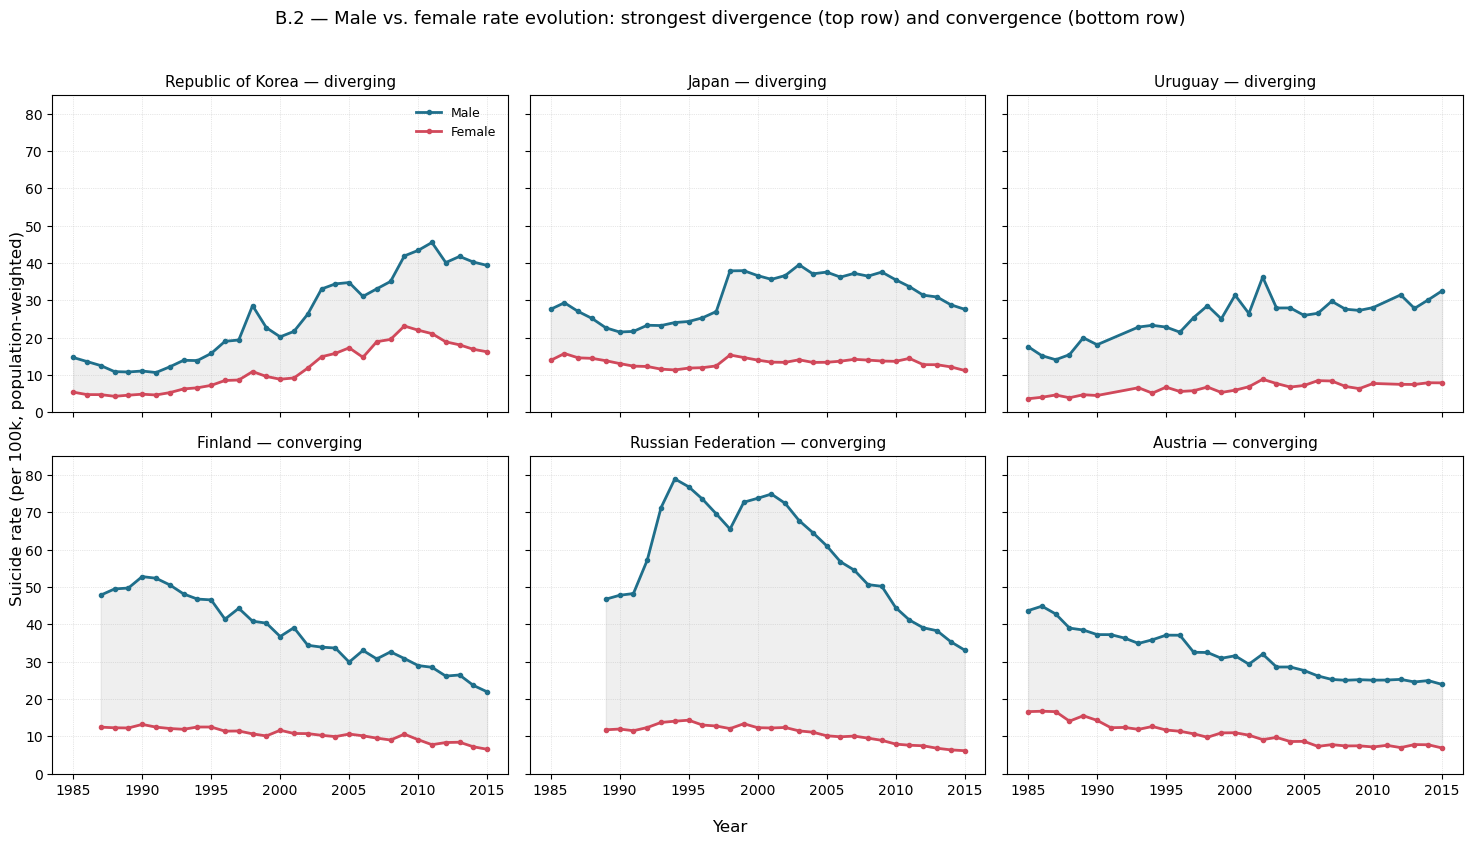

In [5]:
plot_gender_evolution(df)

Describe your visualizations and findings. Be clear which chart(s) you are referring to and relate your findings to the hypothesis/task. Use no more than 150 words and indicate the word count of your description below.

**Description:** The B.2 subplots illustrate male (blue) and female (red) suicide rates over time, with the gray shaded area representing the gender gap. The top row displays the three most diverging countries; the bottom row the three most converging, ranked by linear trend in the male-female gap.
Globally, male rates substantially exceed female rates, though trajectories differ by country. In the diverging group: Korea, Japan, and Uruguay, male rates rise aggressivly while female rates remain low and stable, widening the gap. In the converging group: Finland, Russia, and Austria, initially very high male rates decline sharply toward a low, stable female baseline, narrowing the gap.
This confirms hypothesis B.2: male and female suicide rates have evolved differently across countries. The sharpest divergence occurs in East Asia and Uruguay; the most significant convergence is observed in Europe, particularly in countries with historically extreme male rates.

**Word count**: 143

---

## Results &ndash; Black-Hat Visualization

Place your black hat visualization below. Make sure that everything displays correctly in the GitHub file preview.

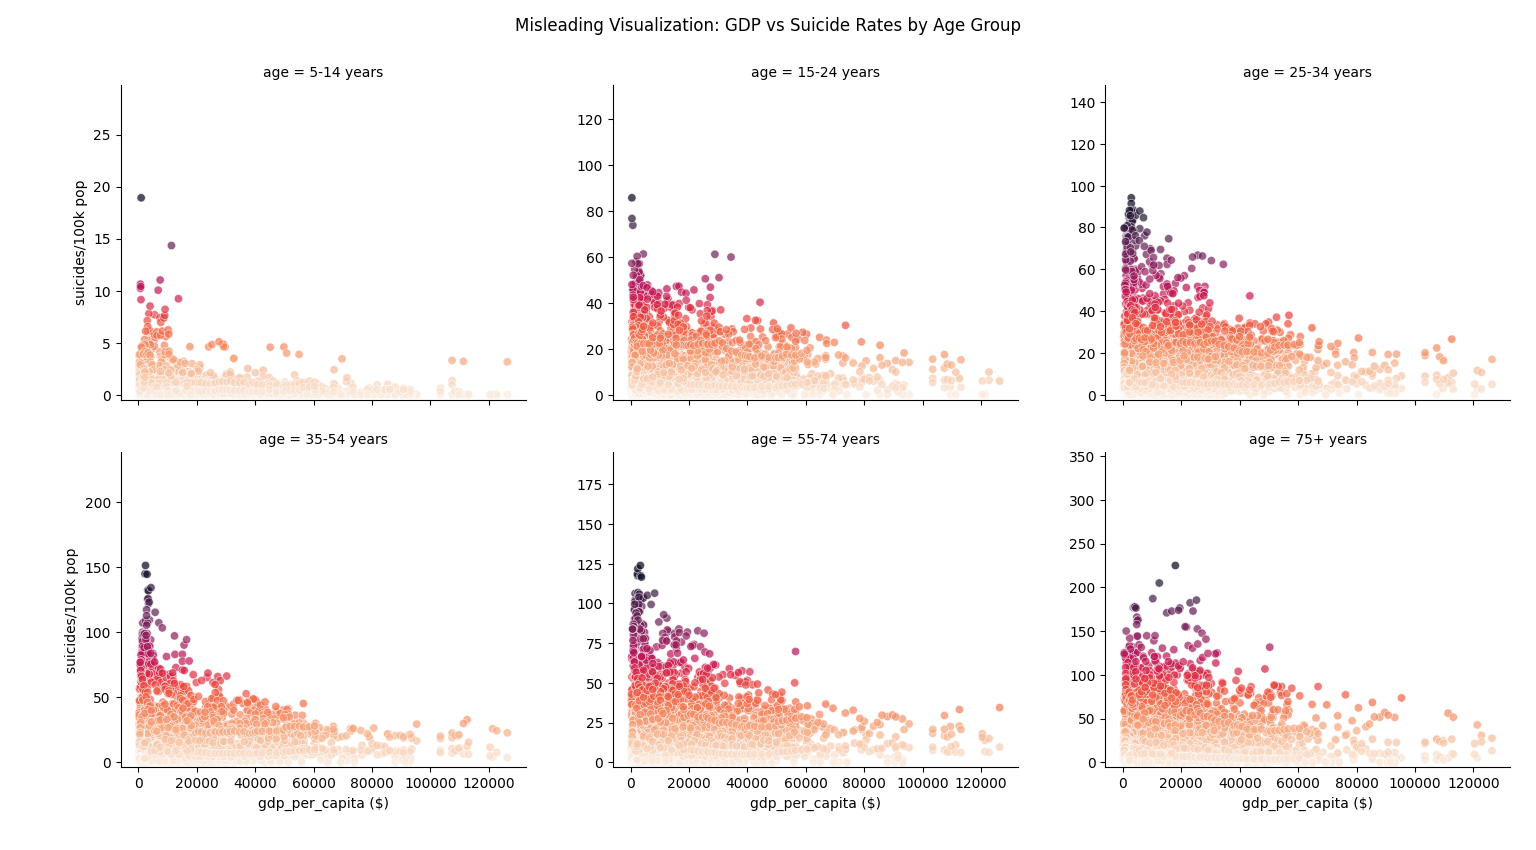

Describe your black-hat visualization. What was your motivation? How did you achieve the desired effect? Use no more than 150 and indicate the word count of your description below.

**Description:**  
We created a Black Hat that foccused on our hypothesis B1. We reversed the GDP per capita axis and aused a different y‑axis limits for each age group. This makes and amplification on the apparent differences between groups and makes weak correlations look stronger than they are. We also selected darker colors to exaggerate high suicide rates. Together, these manipulations mislead the viewer into believing that GDP has a powerful and age‑dependent effect on suicide rates, even though the real relationship is far more subtle.


**Word count:** 85